In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.linear_model import LinearRegression

df = pd.read_csv("../data/clean.csv")

print("Размер датасета:", df.shape)
print("Пропуски:", df.isna().sum().sum())
print("Дубликаты:", df.duplicated().sum())

display(df.head())


Размер датасета: (649, 33)
Пропуски: 0
Дубликаты: 0


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,4,3,4,1,1,3,4,0,11,11
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,5,3,3,1,1,3,2,9,11,11
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,4,3,2,2,3,3,6,12,13,12
3,GP,F,15,U,GT3,T,4,2,health,services,...,3,2,2,1,1,5,0,14,14,14
4,GP,F,16,U,GT3,T,3,3,other,other,...,4,3,2,1,2,5,0,11,13,13


In [2]:
target = "G3"
X = df.drop(columns=["G3", "at_risk"], errors="ignore")
y = df[target]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()

print("Числовых признаков:", len(num_cols))
print("Категориальных признаков:", len(cat_cols))
print("Целевая переменная:", target)


Числовых признаков: 15
Категориальных признаков: 17
Целевая переменная: G3


In [3]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.25,
    random_state=42
)
print("Обучающая выборка:", X_train.shape)
print("Тестовая выборка:", X_test.shape)


Обучающая выборка: (486, 32)
Тестовая выборка: (163, 32)


RIDGE
Лучший alpha: 21.544347
Train RMSE: 1.233051
CV RMSE: 1.328212
CV R²: 0.830479


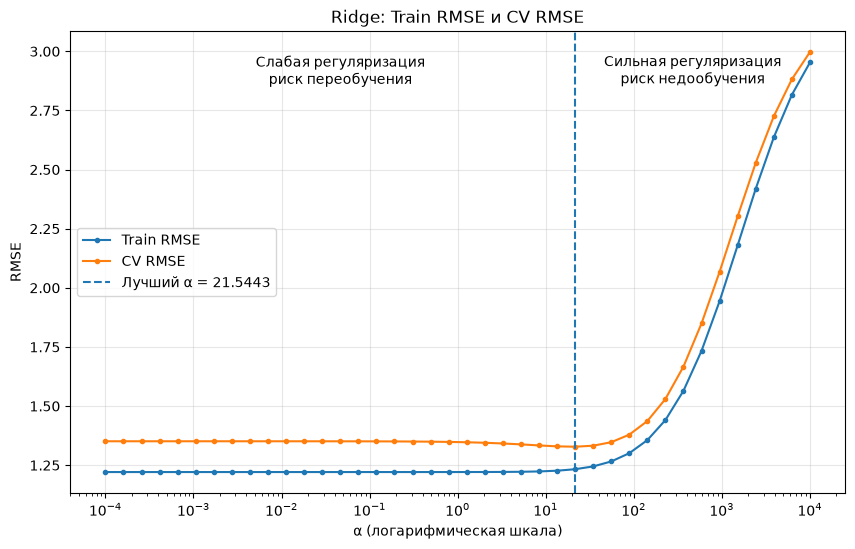

In [9]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.pipeline import make_pipeline
from sklearn.compose import make_column_transformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder,
    KBinsDiscretizer
)
from sklearn.linear_model import Ridge, Lasso, LassoCV
from sklearn.metrics import mean_squared_error

warnings.filterwarnings(
    "ignore",
    message="Bins whose width are too small.*"
)
warnings.filterwarnings(
    "ignore",
    message="The current default behavior, quantile_method.*"
)

df = pd.read_csv("../data/clean.csv")

X = df.drop(columns=["G3", "at_risk"], errors="ignore")
y = df["G3"]

num_cols = X.select_dtypes(include="number").columns.tolist()
cat_cols = X.select_dtypes(exclude="number").columns.tolist()
num_wo = [c for c in num_cols if c != "absences"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42
)

def make_prep_bins(drop=None):
    num = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler()
    )

    bins = make_pipeline(
        SimpleImputer(strategy="median"),
        KBinsDiscretizer(
            n_bins=20,
            encode="onehot",
            strategy="quantile"
        )
    )

    cat = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(
            handle_unknown="ignore",
            drop=drop
        )
    )

    return make_column_transformer(
        (num, num_wo),
        (bins, ["absences"]),
        (cat, cat_cols)
    )

alphas = np.logspace(-4, 4, 40)
ridge_results = []

for alpha in alphas:
    model = make_pipeline(
        make_prep_bins(),
        Ridge(alpha=alpha)
    )

    cv_rmse = -cross_val_score(
        model, X_train, y_train,
        cv=5,
        scoring="neg_root_mean_squared_error"
    ).mean()

    model.fit(X_train, y_train)

    train_rmse = np.sqrt(
        mean_squared_error(
            y_train,
            model.predict(X_train)
        )
    )

    ridge_results.append({
        "alpha": alpha,
        "train_rmse": train_rmse,
        "cv_rmse": cv_rmse
    })

ridge_df = pd.DataFrame(ridge_results)

best = ridge_df.loc[ridge_df["cv_rmse"].idxmin()]
best_alpha = float(best["alpha"])

ridge_model = make_pipeline(
    make_prep_bins(),
    Ridge(alpha=best_alpha)
)

ridge_cv_r2 = cross_val_score(
    ridge_model, X_train, y_train,
    cv=5, scoring="r2"
).mean()

print("RIDGE")
print("Лучший alpha:", round(best_alpha, 6))
print("Train RMSE:", round(best["train_rmse"], 6))
print("CV RMSE:", round(best["cv_rmse"], 6))
print("CV R²:", round(ridge_cv_r2, 6))

fig, ax = plt.subplots(figsize=(10, 6))

ax.semilogx(
    ridge_df["alpha"],
    ridge_df["train_rmse"],
    marker=".",
    label="Train RMSE"
)

ax.semilogx(
    ridge_df["alpha"],
    ridge_df["cv_rmse"],
    marker=".",
    label="CV RMSE"
)

ax.axvline(
    best_alpha,
    linestyle="--",
    label=f"Лучший α = {best_alpha:.4f}"
)

# Обозначаем две зоны
ax.text(
    np.sqrt(alphas[0] * best_alpha),
    0.95,
    "Слабая регуляризация\nриск переобучения",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top"
)

ax.text(
    np.sqrt(best_alpha * alphas[-1]),
    0.95,
    "Сильная регуляризация\nриск недообучения",
    transform=ax.get_xaxis_transform(),
    ha="center",
    va="top"
)

ax.set_xlabel("α (логарифмическая шкала)")
ax.set_ylabel("RMSE")
ax.set_title("Ridge: Train RMSE и CV RMSE")
ax.legend()
ax.grid(alpha=0.3)

plt.show()


In [10]:
lasso_alphas = np.logspace(-4, 1, 60)
lasso_results = []

for drop in [None, "first"]:

    model = make_pipeline(
        make_prep_bins(drop=drop),
        LassoCV(
            alphas=lasso_alphas,
            cv=5,
            random_state=42,
            max_iter=50000
        )
    )

    model.fit(X_train, y_train)

    alpha = float(model[-1].alpha_)
    feature_names = model[0].get_feature_names_out()

    coefs = pd.Series(
        model[-1].coef_,
        index=feature_names
    )
    zeros = coefs[coefs.abs() < 1e-8]

    fixed_model = make_pipeline(
        make_prep_bins(drop=drop),
        Lasso(alpha=alpha, max_iter=50000)
    )

    cv_r2 = cross_val_score(
        fixed_model,
        X_train,
        y_train,
        cv=5,
        scoring="r2"
    ).mean()

    cv_rmse = -cross_val_score(
        fixed_model,
        X_train,
        y_train,
        cv=5,
        scoring="neg_root_mean_squared_error"
    ).mean()

    lasso_results.append({
        "OneHotEncoder": "drop=None" if drop is None else "drop=first",
        "alpha": alpha,
        "cv_r2": cv_r2,
        "cv_rmse": cv_rmse,
        "total_weights": len(coefs),
        "zero_weights": len(zeros)
    })

    print("\n" + "=" * 50)
    print("OneHotEncoder drop =", drop)
    print("Лучший alpha:", round(alpha, 6))
    print("CV R²:", round(cv_r2, 6))
    print("CV RMSE:", round(cv_rmse, 6))
    print("Всего коэффициентов:", len(coefs))
    print("Обнулённых коэффициентов:", len(zeros))

    print("\nПризнаки с нулевыми коэффициентами:")
    display(
        zeros.rename("Коэффициент").to_frame()
    )

    print("\nНаиболее значимые ненулевые коэффициенты:")
    nonzero = coefs[coefs.abs() >= 1e-8]
    display(
        nonzero.reindex(
            nonzero.abs().sort_values(ascending=False).index
        ).head(10).rename("Коэффициент").to_frame()
    )

lasso_df = pd.DataFrame(lasso_results)

print("\nИТОГОВОЕ СРАВНЕНИЕ LASSO")
display(lasso_df.round(6))



OneHotEncoder drop = None
Лучший alpha: 0.051507
CV R²: 0.837774
CV RMSE: 1.299489
Всего коэффициентов: 65
Обнулённых коэффициентов: 53

Признаки с нулевыми коэффициентами:


,Коэффициент
pipeline-1__age,-0.000000e+00
pipeline-1__Fedu,-0.000000e+00
pipeline-1__traveltime,0.000000e+00
pipeline-1__goout,0.000000e+00
pipeline-1__Walc,-0.000000e+00
pipeline-2__absences_1.0,0.000000e+00
pipeline-2__absences_2.0,0.000000e+00
pipeline-2__absences_3.0,0.000000e+00
pipeline-2__absences_4.0,-0.000000e+00
pipeline-2__absences_5.0,0.000000e+00



Наиболее значимые ненулевые коэффициенты:


,Коэффициент
pipeline-1__G2,2.451755
pipeline-1__G1,0.476178
pipeline-2__absences_0.0,-0.220154
pipeline-3__school_GP,0.079354
pipeline-1__failures,-0.047579
pipeline-1__Dalc,-0.045504
pipeline-1__health,-0.033784
pipeline-1__freetime,-0.030654
pipeline-1__studytime,0.025661
pipeline-1__famrel,-0.016716



OneHotEncoder drop = first
Лучший alpha: 0.034864
CV R²: 0.837287
CV RMSE: 1.301371
Всего коэффициентов: 48
Обнулённых коэффициентов: 31

Признаки с нулевыми коэффициентами:


,Коэффициент
pipeline-1__age,0.0
pipeline-1__Fedu,-0.0
pipeline-1__goout,0.0
pipeline-1__Walc,-0.0
pipeline-2__absences_1.0,0.0
pipeline-2__absences_2.0,-0.0
pipeline-2__absences_3.0,0.0
pipeline-2__absences_4.0,-0.0
pipeline-2__absences_5.0,0.0
pipeline-2__absences_6.0,-0.0



Наиболее значимые ненулевые коэффициенты:


,Коэффициент
pipeline-1__G2,2.445822
pipeline-1__G1,0.489128
pipeline-2__absences_0.0,-0.284580
pipeline-3__school_MS,-0.129770
pipeline-3__reason_other,-0.124052
pipeline-3__Mjob_other,-0.097198
pipeline-1__failures,-0.063661
pipeline-1__Medu,-0.054997
pipeline-1__Dalc,-0.053194
pipeline-1__health,-0.049974



ИТОГОВОЕ СРАВНЕНИЕ LASSO


,OneHotEncoder,alpha,cv_r2,cv_rmse,total_weights,zero_weights
0,drop=None,0.051507,0.837774,1.299489,65,53
1,drop=first,0.034864,0.837287,1.301371,48,31
